$Feature$-$Selection$

**Retrival the important features, selecting an important features is very important step before going to ML**

- Droping the constant fetaures ( Regression and classification)

- Information gain (Classification)

- p-value (Regression)

- VIF (Regression)

- Forward selection and backward selection (Regression and classification)

- Correlation with target column ( Regression and classification)

Feature selection methods

1) Variance threshold:
    
    - based on variance we can decide the data is constant or varying
  
    - Data is not varying much means , data has unique values
  
    - For example we have seen in loan dataset, loan term:360
  
    - Python by default will use variance=0, it will drop those fetaures which are having variance=0
  
    - Variance threshold is hyper parameter, we can keep threshold as any value
  
    - based on internal team discussion
  
    - we will drop those fetaure which are having <= threshold value

2) P-value    

    - H0: there is no relation x andy
        
    - H1: There is relation   X and Y
        
    - p<0.05     
    
        - Reject the Null hypothesis:  **Which means do not include the variable**
     
    - p>0.05
  
        - Not Reject the Null hypothesis: **which means include the variables**


3)  Mutual info classify :  
    
    - KNN and entropy

    - It will give the relation between input and output will pick which are having more relation

    - input vs output
    
        - 1) Entropy 
        
        - 2) KNN 
        
        - 3) R-square: explainability about y based on x

4) Forward selection and backward selection
     
     https://courses.lumenlearning.com/introstats1/chapter/model-selection/#:~:text=The%20forward%20selection%20strategy%20is,measured%20by%20adjusted%20R2).

   **Forward selection method**

       - Start with empty set of features

       - Iterate throuh each feature and select the one feature that improves model performance

       - Continue adding fetaures one by one till we meet our creteria

   **Backward selection mehod**

       - Start with full set of features
  
       - Iterate through each feature by removing the feature which is having less impact on the model
  
       - Continue the process, till your performance is stable
  
- Both Forward selection and Bcakward selection methods are complex in nature

- More time taken, will avoid in general
    
5) **Variance inflation factor**(VIF):

    - VIF will give the analysis of multicollinearity

    - In VIF will find the R-Square value of each input feature wrt to other input fetaure

    - Will keep one fetaure as input and  other fetaure are consider as output in Regression equation

    - This will keep on iterate through all fetaure

    - Every feature behave as input as well as output

    - As we know every regression line give Rsqurae value from that value will fine VIF

    - will drop the feature which are having VIF>5 or VIF >10 based on iternal team discussion

   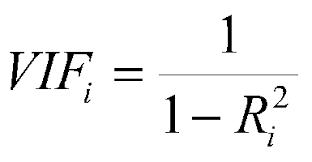

$Method-1$:  Variance threshold method

**Droping constanat fetaures**

- If the features or variables having zero varinace

- the feature values through out the data is the same

- you can decide manually what is your desired variance in order to keep the feature

In [1]:
import pandas as pd
dict1={'A':[100,200,300,400],
       'B':[1,2,3,4],
       'C':[10,20,30,40],
       'D':[10,10,10,10]}

df=pd.DataFrame(dict1)
df

,A,B,C,D
0,100,1,10,10
1,200,2,20,10
2,300,3,30,10
3,400,4,40,10


In [2]:
from sklearn.feature_selection import VarianceThreshold
vt=VarianceThreshold(threshold=0)
# Threshold variance value
# we want to drop the feaure based on threshold
vt.fit(df)

VarianceThreshold(threshold=0)

In [3]:
dir(vt)

['__abstractmethods__',
 '__annotations__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__sklearn_clone__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_abc_impl',
 '_build_request_for_signature',
 '_check_feature_names',
 '_check_n_features',
 '_get_default_requests',
 '_get_metadata_request',
 '_get_param_names',
 '_get_support_mask',
 '_get_tags',
 '_more_tags',
 '_parameter_constraints',
 '_repr_html_',
 '_repr_html_inner',
 '_repr_mimebundle_',
 '_sklearn_auto_wrap_output_keys',
 '_transform',
 '_validate_data',
 '_validate_params',
 'feature_names_in_',
 'fit',
 'fit_transform',
 'get_feature_names_out',
 'get_metadata_routing',
 'get_params',
 'get_support',
 'inve

In [3]:
vt.variances_
# 300 is first column variance (T)
# 1.25 is second column variance (T)
# 30 is column varaince (T)
# 0  is fourth column variance (F)

array([300.  ,   1.25,  30.  ,   0.  ])

In [5]:
vt.get_support()

array([ True,  True,  True, False])

In [7]:
vt.get_params()
# Hyper parameter 
# that we are providing inside the function

{'threshold': 0}

In [8]:
vt.threshold

0

In [11]:
cols=vt.get_feature_names_out()
# These fetaure only we want include
df[cols]

,A,B,C
0,100,1,10
1,200,2,20
2,300,3,30
3,400,4,40


In [14]:
## Apply on wine dataset
## Read the data
## Keep the threshold : 0,0.1
## Get the new data

df = pd.read_csv("C:\\Users\\omkar\\OneDrive\\Documents\\Data science\\Naresh IT\\Datafiles\\winequality_red.csv")
from sklearn.feature_selection import VarianceThreshold
vt=VarianceThreshold(threshold=0)
### Make sure before fitting the dataframe , do not include output column
X=df.drop('quality',axis=1) 
# X it self a data frame
vt.fit(X)
vt.variances_
vt.get_support()
cols=vt.get_feature_names_out()
X[cols]

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4
...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2


In [6]:
df  

# The column D is not changing
# The column D has same values
# Same values means the variance =0
# I keep threshld=0
# D should remove

#df[['A','B','C']]
#df[[True,True,True,False]]
#df[vt.get_support()]

,A,B,C,D
0,100,1,10,10
1,200,2,20,10
2,300,3,30,10
3,400,4,40,10


In [4]:
vt.get_support()

# True : the variance not equal to zero
# False: the variance is equal to zero

array([ True,  True,  True, False])

In [5]:
# I need the columns those have support=True
df.columns

Index(['A', 'B', 'C', 'D'], dtype='object')

if the values are constant and if one value is zero we will remove that row or column?

 - you want to drop the columns: if that column is useless
    
 - the data is not changing much:variance is zero

In [7]:
vt.get_params() # What is the threshold value it is using

{'threshold': 0}

In [7]:
vt.get_support()

array([ True,  True,  True, False])

In [5]:
cols=df.columns[vt.get_support()]  
cols
# D is removed

Index(['A', 'B', 'C'], dtype='object')

In [6]:
# Normal python implementation
# support=vt.get_support()
# for i in range(len(support)):
#     if support[i]==True:
#         print(df.columns[i])

In [ ]:
# Task: implememt the same task on wine data
# change the threshold  
# keep 0
# keep 0.5

# keep that in mind dont drop output column

df=#data
from sklearn.feature_selection import VarianceThreshold
vt=VarianceThreshold(threshold=0)
vt.fit(df)

cols=df.columns[vt.get_support()]  
cols

In [10]:
df

,A,B,C,D
0,100,1,10,10
1,200,2,20,10
2,300,3,30,10
3,400,4,40,10


In [11]:
df[cols]

,A,B,C
0,100,1,10
1,200,2,20
2,300,3,30
3,400,4,40


In [13]:
from sklearn.feature_selection import VarianceThreshold
vt=VarianceThreshold(threshold=0)
vt.fit(df)
cols=df.columns[vt.get_support()]  
df[cols]

# Dont do on Target varaible
# while providng the data remove the target variables

,A,B,C
0,100,1,10
1,200,2,20
2,300,3,30
3,400,4,40


In [24]:
import pandas as pd

data=pd.read_csv("C:\\Users\\omkar\\OneDrive\\Documents\\Data science\\Naresh IT\\Datafiles\\winequality_red.csv")
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [25]:
# Apply only Input columns
# drop the target column: quality
data.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

In [39]:
# Seperate input and output column
X=data.drop('quality',axis=1) 
# inplace =True  data will with out quality  
# dont apply inplace True
X.columns
print(X.shape)
y=data['quality']

(1599, 11)


In [ ]:
# Here in two examples I have taken numerical data
# Will convert categorical data to numerical data before developing the ML algorithm
# thats why here im using only numerical data

In [40]:
from sklearn.feature_selection import VarianceThreshold
vt=VarianceThreshold(threshold=1)
vt.fit(X)
cols=X.columns[vt.get_support()]
X[cols]

,fixed acidity,residual sugar,free sulfur dioxide,total sulfur dioxide,alcohol
0,7.4,1.9,11.0,34.0,9.4
1,7.8,2.6,25.0,67.0,9.8
2,7.8,2.3,15.0,54.0,9.8
3,11.2,1.9,17.0,60.0,9.8
4,7.4,1.9,11.0,34.0,9.4
...,...,...,...,...,...
1594,6.2,2.0,32.0,44.0,10.5
1595,5.9,2.2,39.0,51.0,11.2
1596,6.3,2.3,29.0,40.0,11.0
1597,5.9,2.0,32.0,44.0,10.2


In [ ]:
if complete row is NaN can we drop NaN values

# many approaches ===== R &D 
# 100 : 50 NaN 

In [51]:
import pandas as pd

data=pd.read_csv("C:\\Users\\omkar\\OneDrive\\Documents\\Data science\\Naresh IT\\Datafiles\\winequality_red.csv")
data.head()

X=data.drop('quality',axis=1) 
y=data['quality']

from sklearn.feature_selection import VarianceThreshold
vt=VarianceThreshold()  # default threshold=0.0
vt.fit(X)
cols=X.columns[vt.get_support()]  # Variance=0
X[cols]

# what is the threshold you need to keep: no answer

# pH column is not removed which means its variance is not zero

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4
...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2


In [52]:
X['pH'].std()

0.15438646490354266

In [41]:
data.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [14]:
import pandas as pd

data=pd.read_csv("C:\\Users\\omkar\\OneDrive\\Documents\\Data science\\Naresh IT\\Datafiles\\winequality_red.csv")
data.head()

X=data.drop('quality',axis=1) 
y=data['quality']

In [25]:
import numpy as np
list_var=[]
for i in X.columns:
    list_var.append(np.sqrt(X[i].std()))
    
for i in list_var:
    if i<1:
        print(i,list_var.index(i),X.columns[list_var.index(i)])

0.42315446843148774 1 volatile acidity
0.44136281833126567 2 citric acid
0.21694538946492997 4 chlorides
0.04344345697389373 7 density
0.39292043075353394 8 pH
0.41171225338834616 9 sulphates


In [22]:
list1=['A','B']
list1.index('A')

0

$Method-2$:
    
**Information gain**

mutual info classify


- It is value estimating how much relationship/how much information about target variable

- 0 mean both variables are independent

- Here will use entropy or KNN method

In [15]:
import pandas as pd

# Read the data
data=pd.read_csv("C:\\Users\\omkar\\OneDrive\\Documents\\Data science\\Naresh IT\\Datafiles\\winequality_red.csv")

#Sepearte input and target features
X=data.drop('quality',axis=1) # X is dataframe
y=data['quality']   # y is series type

In [16]:
data.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

In [ ]:
#data[['fixed acidity', 'volatile acidity']]

In [10]:
#YY=data['quality']
#YY

In [17]:
from sklearn.feature_selection import mutual_info_classif
MI=mutual_info_classif(X,y)
MI

array([0.04192342, 0.13248533, 0.07643552, 0.03341763, 0.02377278,
       0.0263798 , 0.09404301, 0.08315899, 0.02468633, 0.09998669,
       0.16912481])

In [19]:
import numpy as np
np.sum(MI)

0.805414325889455

In [28]:
len(MI)

11

In [26]:
d=pd.DataFrame(MI,
             columns=['Information gain'],
             index=X.columns)
d.sort_values('Information gain',ascending=False)

# we need to select manaualy
# How about python will provide top 5 or top 10 or top k
# SelectKBest

,Information gain
alcohol,0.169125
volatile acidity,0.132485
sulphates,0.099987
total sulfur dioxide,0.094043
density,0.083159
citric acid,0.076436
fixed acidity,0.041923
residual sugar,0.033418
free sulfur dioxide,0.026380
pH,0.024686


In [20]:
val=pd.Series(MI)
val

# I want replace index with column names

0     0.041923
1     0.132485
2     0.076436
3     0.033418
4     0.023773
5     0.026380
6     0.094043
7     0.083159
8     0.024686
9     0.099987
10    0.169125
dtype: float64

In [13]:
#y

In [12]:
#MI  # numpy array

# Numpy array we are converting into series

In [14]:
# Two methods almost enough
# Constan features ==== you need to remove
# Mutual information
val=pd.Series(MI)    # index with series
val.index=X.columns  # column with series
val

fixed acidity           0.051143
volatile acidity        0.139092
citric acid             0.064499
residual sugar          0.029588
chlorides               0.040416
free sulfur dioxide     0.026377
total sulfur dioxide    0.103364
density                 0.086678
pH                      0.036339
sulphates               0.084093
alcohol                 0.178708
dtype: float64

In [15]:
val.sort_values(ascending=True)


free sulfur dioxide     0.026377
residual sugar          0.029588
pH                      0.036339
chlorides               0.040416
fixed acidity           0.051143
citric acid             0.064499
sulphates               0.084093
density                 0.086678
total sulfur dioxide    0.103364
volatile acidity        0.139092
alcohol                 0.178708
dtype: float64

<Axes: >

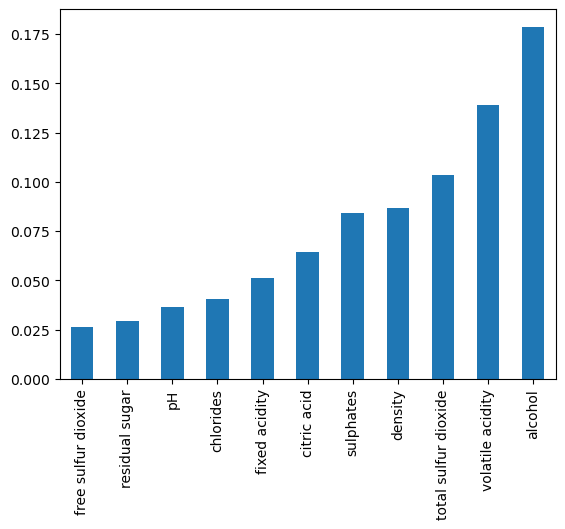

In [16]:
val.sort_values(ascending=True).plot(kind='bar')


is this suitable for both classification and regression sir mutual info

at which step will do these feature selection

why we are splitting : x and y
    
python code will allow X and y sepeartely

thats why we are splitting

ones we extract the important fetaures , those features used to develop a model



[0.06209034 0.1151309  0.05305306 0.04103118 0.03186552 0.01151989
 0.08234434 0.08410012 0.01538596 0.11026483 0.17567737]
0     0.062090
1     0.115131
2     0.053053
3     0.041031
4     0.031866
5     0.011520
6     0.082344
7     0.084100
8     0.015386
9     0.110265
10    0.175677
dtype: float64
fixed acidity           0.062090
volatile acidity        0.115131
citric acid             0.053053
residual sugar          0.041031
chlorides               0.031866
free sulfur dioxide     0.011520
total sulfur dioxide    0.082344
density                 0.084100
pH                      0.015386
sulphates               0.110265
alcohol                 0.175677
dtype: float64


<Axes: >

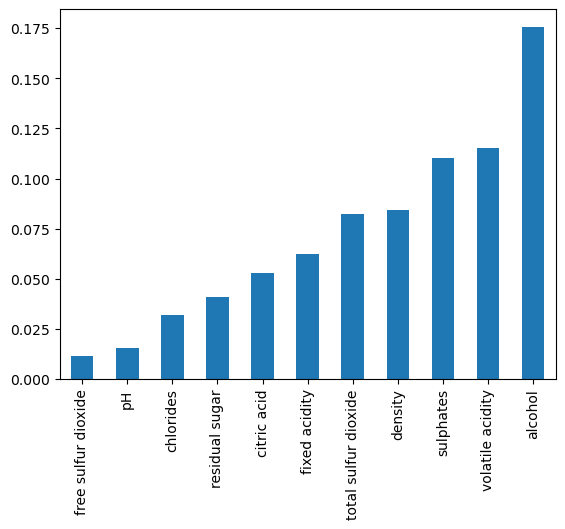

In [3]:
import pandas as pd

# Read the data
data=pd.read_csv("C:\\Users\\omkar\\OneDrive\\Documents\\Data science\\Naresh IT\\Datafiles\\winequality_red.csv")

#Sepearte input and target features
X=data.drop('quality',axis=1) 
y=data['quality']

from sklearn.feature_selection import mutual_info_classif
MI=mutual_info_classif(X,y)

print(MI)

val=pd.Series(MI)
print(val)
val.index=X.columns

val.sort_values(ascending=True)

print(val)

val.sort_values(ascending=True).plot(kind='bar')

In [63]:
val.sort_values(ascending=True).index[:5]

Index(['residual sugar', 'pH', 'chlorides', 'free sulfur dioxide',
       'fixed acidity'],
      dtype='object')

$SelectKbest$

In [50]:
data=pd.read_csv("C:\\Users\\omkar\\OneDrive\\Documents\\Data science\\Naresh IT\\Datafiles\\winequality_red.csv")
data.head()               

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [27]:
from sklearn.feature_selection import SelectKBest,mutual_info_classif
import pandas as pd

# Read the data
data=pd.read_csv("C:\\Users\\omkar\\OneDrive\\Documents\\Data science\\Naresh IT\\Datafiles\\winequality_red.csv")

#Sepearte input and target features
X=data.drop('quality',axis=1) 
y=data['quality']

# Assume that you did not done mutual info classii
top_5=SelectKBest(mutual_info_classif,k=5)
val=top_5.fit(X,y)

In [51]:
dir(val)

['__abstractmethods__',
 '__annotations__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_abc_impl',
 '_check_feature_names',
 '_check_n_features',
 '_check_params',
 '_get_param_names',
 '_get_support_mask',
 '_get_tags',
 '_more_tags',
 '_parameter_constraints',
 '_repr_html_',
 '_repr_html_inner',
 '_repr_mimebundle_',
 '_sklearn_auto_wrap_output_keys',
 '_transform',
 '_validate_data',
 '_validate_params',
 'feature_names_in_',
 'fit',
 'fit_transform',
 'get_feature_names_out',
 'get_params',
 'get_support',
 'inverse_transform',
 'k',
 'n_features_in_',
 'pvalues_',
 'score_func',
 'scores_',
 'set_output',
 'set_params',
 't

In [2]:
val.get_support()

array([False,  True, False, False, False, False,  True,  True, False,
        True,  True])

In [3]:
val.get_feature_names_out()  # Which is True 

array(['volatile acidity', 'total sulfur dioxide', 'density', 'sulphates',
       'alcohol'], dtype=object)

In [4]:
val.get_params()  # whatever you pass inside package

{'k': 5,
 'score_func': <function sklearn.feature_selection._mutual_info.mutual_info_classif(X, y, *, discrete_features='auto', n_neighbors=3, copy=True, random_state=None)>}

In [5]:
val.scores_

array([0.0476937 , 0.11770635, 0.06547182, 0.02824714, 0.03050792,
       0.03020679, 0.07129996, 0.08042289, 0.02339935, 0.10405392,
       0.19669332])